In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")
df["text"] = df["headline"] + " " + df["body_text"]

print(df["label"].value_counts())

label
Fake    1110
Real    1102
Name: count, dtype: int64


In [3]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

In [4]:
sentiment_scores = df["text"].apply(
    lambda text: analyzer.polarity_scores(str(text))
)

sentiment_df = pd.DataFrame(sentiment_scores.tolist())

df[["positive", "negative", "neutral", "compound"]] = sentiment_df

print(df[["label", "positive", "negative", "neutral", "compound"]].head())

  label  positive  negative  neutral  compound
0  Real     0.167     0.833      0.0   -0.4215
1  Real     0.180     0.820      0.0   -0.5106
2  Fake     0.000     1.000      0.0    0.0000
3  Fake     0.162     0.838      0.0   -0.4767
4  Real     0.176     0.824      0.0   -0.4939


In [5]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["compound"].apply(classify_sentiment)

print(df[["label", "compound", "sentiment"]].head())

  label  compound sentiment
0  Real   -0.4215  Negative
1  Real   -0.5106  Negative
2  Fake    0.0000   Neutral
3  Fake   -0.4767  Negative
4  Real   -0.4939  Negative


In [6]:
# Compare the average sentiment scores for both categories
sentiment_comparison = df.groupby("label")[
    ["positive", "negative", "neutral", "compound"]
].mean().round(3)

print(sentiment_comparison)

       positive  negative  neutral  compound
label                                       
Fake      0.129     0.804    0.067    -0.182
Real      0.127     0.802    0.071    -0.166


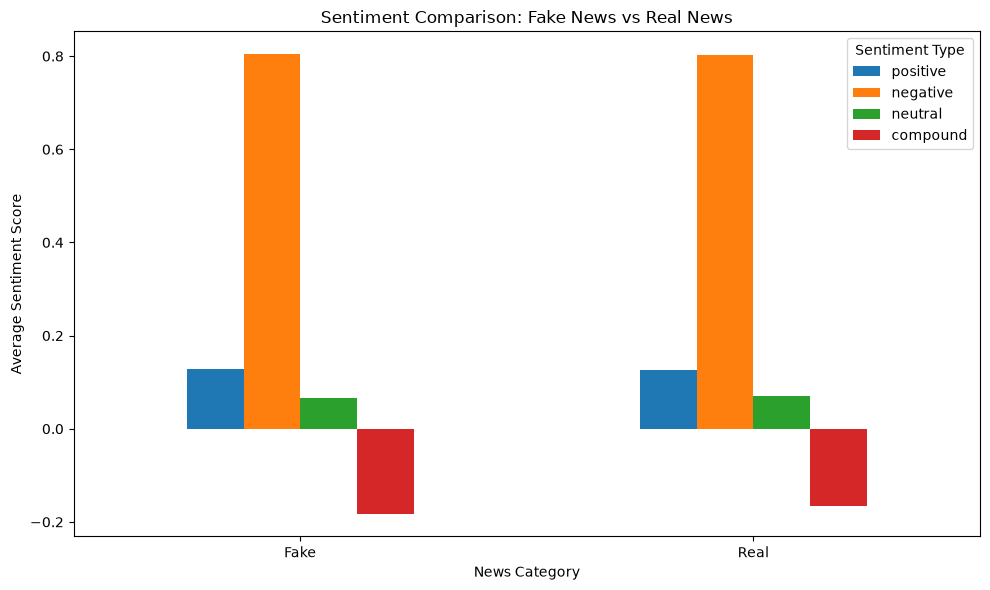

In [7]:
# average sentiment scores to compare both categories
sentiment_comparison.plot(kind="bar", figsize=(10, 6))

plt.title("Sentiment Comparison: Fake News vs Real News")
plt.xlabel("News Category")
plt.ylabel("Average Sentiment Score")
plt.xticks(rotation=0)
plt.legend(title="Sentiment Type")
plt.tight_layout()
plt.show()

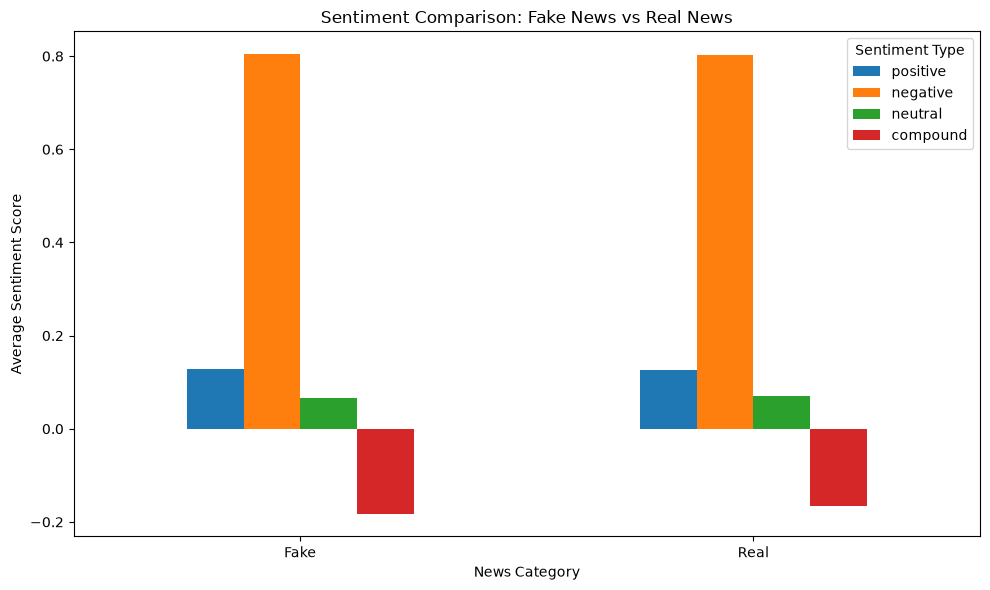

In [8]:
# average sentiment scores to compare both categories
sentiment_comparison.plot(kind="bar", figsize=(10, 6))

plt.title("Sentiment Comparison: Fake News vs Real News")
plt.xlabel("News Category")
plt.ylabel("Average Sentiment Score")
plt.xticks(rotation=0)
plt.legend(title="Sentiment Type")
plt.tight_layout()
plt.show()

sentiment  Negative  Neutral  Positive
label                                 
Fake          55.59    24.14     20.27
Real          53.54    22.32     24.14


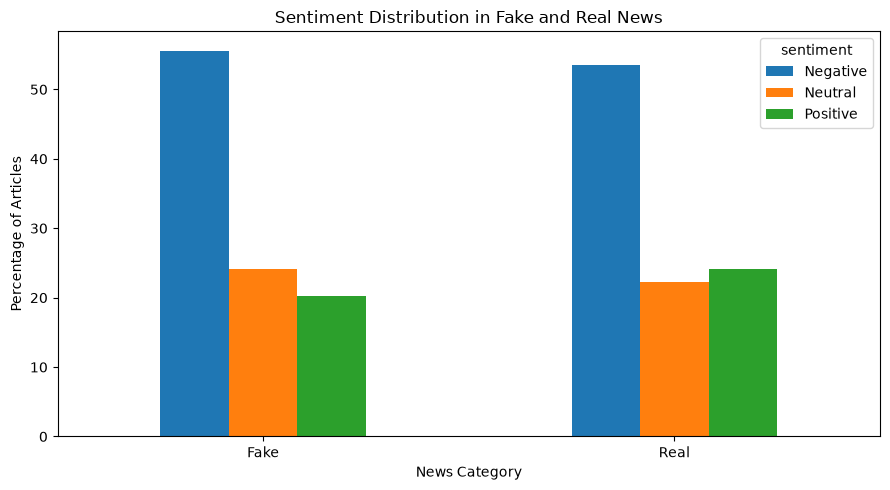

In [9]:
# Countedd how many articles fall into each sentiment category
sentiment_distribution = pd.crosstab(
    df["label"], df["sentiment"], normalize="index"
) * 100

print(sentiment_distribution.round(2))

sentiment_distribution.plot(kind="bar", figsize=(9, 5))

plt.title("Sentiment Distribution in Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Percentage of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Save the sentiment scores and comparison results
df.to_csv("T31_vader_sentiment_analysis.csv", index=False)
sentiment_comparison.to_csv("T31_sentiment_comparison.csv")
sentiment_distribution.to_csv("T31_sentiment_distribution.csv")

print("Sentiment analysis completed and files saved successfully!")

Sentiment analysis completed and files saved successfully!
